**Goal:** Evaluate how different modeling approaches perform when predicting household expenditure, particularly when trained on older survey data and applied to newer surveys.

**Objective (supervised learning):**
- Predict household-level expenditure from survey covariates (household size, education, employment, housing conditions, access to services, etc.)
- Compare predictive performance of machine learning algorithms for household expenditure.

In [70]:
# loading packages
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# EDA
Let's get to know the data:
- train_hh_features.csv is our main dataset.
- feature_description.csv file provides variable labels for all features.
- feature_value_descriptions.csv file provides value descriptions for binary and categorical variables. 

Main dataset: 
- Household sampling weights are available.
- `cons_ppp17` is the _outcome/target variable_.


In [71]:
consumption = pd.read_csv("../data/train_hh_gt.csv")
consumption.head()

,survey_id,hhid,cons_ppp17
0,100000,100001,25.258402
1,100000,100002,16.996706
2,100000,100003,13.671848
3,100000,100004,7.189475
4,100000,100005,12.308855


In [72]:
df = pd.read_csv("../data/train_hh_features.csv")
df.head()

,hhid,com,weight,strata,utl_exp_ppp17,male,hsize,num_children5,num_children10,num_children18,...,consumed4200,consumed4300,consumed4400,consumed4500,consumed4600,consumed4700,consumed4800,consumed4900,consumed5000,survey_id
0,100001,1,75,4,594.80627,Female,1,0,0,0,...,Yes,No,No,No,Yes,Yes,Yes,Yes,No,100000
1,100002,1,150,4,1676.27230,Female,2,0,0,0,...,Yes,No,No,No,No,Yes,Yes,No,No,100000
2,100003,1,375,4,506.93719,Male,5,0,0,2,...,Yes,Yes,No,Yes,Yes,Yes,Yes,No,Yes,100000
3,100004,1,375,4,824.61786,Male,5,0,0,1,...,No,Yes,No,No,No,Yes,Yes,No,No,100000
4,100005,1,525,4,351.47644,Male,7,1,0,0,...,Yes,No,No,Yes,No,Yes,Yes,Yes,No,100000


In [73]:
print(consumption.shape, df.shape)

(104234, 3) (104234, 88)


In [74]:
# merge consumption data to main df
df = df.merge(consumption, how= "left", on=["hhid", "survey_id"], validate="1:1")

In [75]:
df.columns # many binary consumption variables that capture consumption of different food items.

Index(['hhid', 'com', 'weight', 'strata', 'utl_exp_ppp17', 'male', 'hsize',
       'num_children5', 'num_children10', 'num_children18', 'age', 'owner',
       'water', 'toilet', 'sewer', 'elect', 'water_source',
       'sanitation_source', 'dweltyp', 'num_adult_female', 'num_adult_male',
       'num_elderly', 'employed', 'sworkershh', 'share_secondary', 'educ_max',
       'sfworkershh', 'any_nonagric', 'sector1d', 'region1', 'region2',
       'region3', 'region4', 'region5', 'region6', 'region7', 'urban',
       'consumed100', 'consumed200', 'consumed300', 'consumed400',
       'consumed500', 'consumed600', 'consumed700', 'consumed800',
       'consumed900', 'consumed1000', 'consumed1100', 'consumed1200',
       'consumed1300', 'consumed1400', 'consumed1500', 'consumed1600',
       'consumed1700', 'consumed1800', 'consumed1900', 'consumed2000',
       'consumed2100', 'consumed2200', 'consumed2300', 'consumed2400',
       'consumed2500', 'consumed2600', 'consumed2700', 'consumed2800',
 

In [76]:
feature_desc = pd.read_csv("../data/feature_descriptions.csv")
feature_desc

,Variable name,Storage type,Variable label
0,sample,str8,Data Type
1,hhid,int,Household unique identifier
2,com,byte,Identifier of household member
3,weight,int,Household sampling weight
4,strata,byte,Stratification variable
...,...,...,...
103,_pline75,float,Poverty line: 75th percentile of welfare distr...
104,_pline80,float,Poverty line: 80th percentile of welfare distr...
105,_pline85,float,Poverty line: 85th percentile of welfare distr...
106,_pline90,float,Poverty line: 90th percentile of welfare distr...


In [77]:
features = pd.read_csv("../data/feature_value_descriptions.csv")
features

,Variable name,Variable label,Value,Value label
0,any_nonagric,Any household member working in non-agricultur...,0,No
1,any_nonagric,Any household member working in non-agricultur...,1,Yes
2,consumed100,Breads,0,No
3,consumed100,Breads,1,Yes
4,consumed1000,Poultry offal,0,No
...,...,...,...,...
174,water_source,Sources of drinking water,10,Unprotected dug well
175,water_source,Sources of drinking water,11,Cart with small tank/drum
176,water_source,Sources of drinking water,12,Tanker-truck
177,water_source,Sources of drinking water,13,Surface water


## Data exploration and feature engeneering 
1. Explore numeric variables
2. Explore categorical and binary variables


In [78]:
df.dtypes.value_counts()

str        64
int64      20
float64     5
Name: count, dtype: int64

In [79]:
df.head()

,hhid,com,weight,strata,utl_exp_ppp17,male,hsize,num_children5,num_children10,num_children18,...,consumed4300,consumed4400,consumed4500,consumed4600,consumed4700,consumed4800,consumed4900,consumed5000,survey_id,cons_ppp17
0,100001,1,75,4,594.80627,Female,1,0,0,0,...,No,No,No,Yes,Yes,Yes,Yes,No,100000,25.258402
1,100002,1,150,4,1676.27230,Female,2,0,0,0,...,No,No,No,No,Yes,Yes,No,No,100000,16.996706
2,100003,1,375,4,506.93719,Male,5,0,0,2,...,Yes,No,Yes,Yes,Yes,Yes,No,Yes,100000,13.671848
3,100004,1,375,4,824.61786,Male,5,0,0,1,...,Yes,No,No,No,Yes,Yes,No,No,100000,7.189475
4,100005,1,525,4,351.47644,Male,7,1,0,0,...,No,No,Yes,No,Yes,Yes,Yes,No,100000,12.308855


In [80]:
df_num = df.select_dtypes(include= ["int", "float"])
df_num

,hhid,com,weight,strata,utl_exp_ppp17,hsize,num_children5,num_children10,num_children18,age,...,sfworkershh,region1,region2,region3,region4,region5,region6,region7,survey_id,cons_ppp17
0,100001,1,75,4,594.80627,1,0,0,0,75,...,0.0,0,1,0,0,0,0,0,100000,25.258402
1,100002,1,150,4,1676.27230,2,0,0,0,61,...,0.0,0,1,0,0,0,0,0,100000,16.996706
2,100003,1,375,4,506.93719,5,0,0,2,49,...,0.5,0,1,0,0,0,0,0,100000,13.671848
3,100004,1,375,4,824.61786,5,0,0,1,58,...,0.2,0,1,0,0,0,0,0,100000,7.189475
4,100005,1,525,4,351.47644,7,1,0,0,57,...,0.5,0,1,0,0,0,0,0,100000,12.308855
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104229,337458,1,616,7,143.58849,4,2,1,0,33,...,0.0,0,0,0,0,1,0,0,300000,2.830888
104230,337459,1,616,7,268.44803,4,0,0,1,48,...,0.0,0,0,0,0,1,0,0,300000,3.144309
104231,337460,1,1540,7,243.47612,10,2,3,2,54,...,0.0,0,0,0,0,1,0,0,300000,3.319158
104232,337461,1,1232,7,337.12079,8,0,0,3,49,...,0.4,0,0,0,0,1,0,0,300000,6.088739


In [81]:
# features to drop
df_num.drop(columns = ["survey_id", "strata", "com", "hhid"], inplace = True)

C:\Users\orxan\AppData\Local\Temp\ipykernel_9568\452089681.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_num.drop(columns = ["survey_id", "strata", "com", "hhid"], inplace = True)


<function matplotlib.pyplot.show(close=None, block=None)>

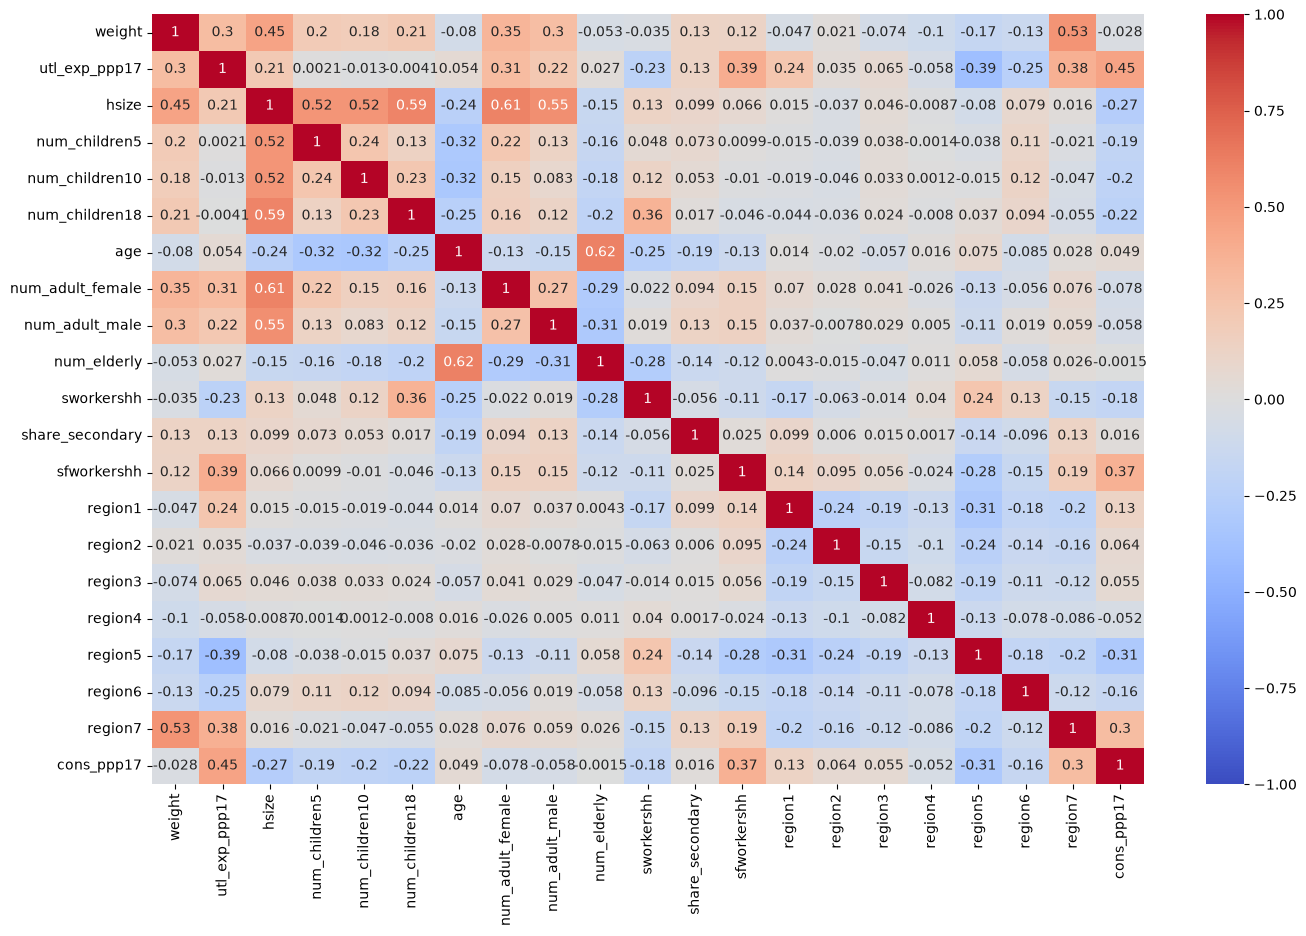

In [82]:
plt.figure(figsize= (16,10))
sns.heatmap(df_num.corr(), annot = True, vmin= -1, vmax= 1, cmap= "coolwarm");
plt.show

In [83]:
df_cat = df.select_dtypes(include= ["str"])
df_cat

,male,owner,water,toilet,sewer,elect,water_source,sanitation_source,dweltyp,employed,...,consumed4100,consumed4200,consumed4300,consumed4400,consumed4500,consumed4600,consumed4700,consumed4800,consumed4900,consumed5000
0,Female,Owner,Access,Access,Access,Access,Piped water into dwelling,A piped sewer system,Detached house,Not employed,...,Yes,Yes,No,No,No,Yes,Yes,Yes,Yes,No
1,Female,Owner,Access,Access,Access,Access,Piped water into dwelling,A piped sewer system,Detached house,Not employed,...,Yes,Yes,No,No,No,No,Yes,Yes,No,No
2,Male,Owner,Access,Access,Access,Access,Piped water into dwelling,A piped sewer system,Detached house,Employed,...,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,No,Yes
3,Male,Not owner,Access,Access,Access,No access,Piped water into dwelling,A piped sewer system,Detached house,Employed,...,No,No,Yes,No,No,No,Yes,Yes,No,No
4,Male,Owner,Access,Access,Access,Access,Piped water into dwelling,A piped sewer system,Detached house,Employed,...,Yes,Yes,No,No,Yes,No,Yes,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104229,Female,Owner,No access,No access,No access,Access,Public tap or standpipe,No facilities or bush or field,Detached house,Employed,...,Yes,Yes,No,No,No,No,Yes,Yes,No,Yes
104230,Female,Owner,No access,No access,No access,Access,Public tap or standpipe,Pit latrine with slab,Detached house,Not employed,...,No,Yes,No,No,No,No,Yes,No,No,No
104231,Male,Owner,No access,Access,No access,Access,Protected spring,A septic tank,Detached house,Not employed,...,Yes,Yes,No,No,Yes,No,Yes,Yes,No,No
104232,Male,Owner,No access,No access,No access,Access,Public tap or standpipe,Pit latrine with slab,Detached house,Employed,...,Yes,Yes,Yes,No,Yes,No,No,Yes,Yes,Yes


In [84]:
# select categorical and binary variables that are likely determinants of poverty based on literature. 
df_cat = df_cat[["male", "owner", "water", "toilet", "elect", "dweltyp", "employed", "educ_max",  "any_nonagric", "urban"]]

In [85]:
df = df.loc[:, df.columns.isin(df_cat.columns) | df.columns.isin(df_num.columns)]
df.head()

,weight,utl_exp_ppp17,male,hsize,num_children5,num_children10,num_children18,age,owner,water,...,any_nonagric,region1,region2,region3,region4,region5,region6,region7,urban,cons_ppp17
0,75,594.80627,Female,1,0,0,0,75,Owner,Access,...,No,0,1,0,0,0,0,0,Urban,25.258402
1,150,1676.27230,Female,2,0,0,0,61,Owner,Access,...,No,0,1,0,0,0,0,0,Urban,16.996706
2,375,506.93719,Male,5,0,0,2,49,Owner,Access,...,Yes,0,1,0,0,0,0,0,Urban,13.671848
3,375,824.61786,Male,5,0,0,1,58,Not owner,Access,...,Yes,0,1,0,0,0,0,0,Urban,7.189475
4,525,351.47644,Male,7,1,0,0,57,Owner,Access,...,Yes,0,1,0,0,0,0,0,Urban,12.308855


In [86]:
df.duplicated().sum()

np.int64(0)

In [92]:
df.info()
# missing values in utl_exp_ppp, dweltyp, share_secondary, educ_max

<class 'pandas.DataFrame'>
RangeIndex: 104234 entries, 0 to 104233
Data columns (total 31 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   weight            104234 non-null  int64  
 1   utl_exp_ppp17     104149 non-null  float64
 2   male              104234 non-null  str    
 3   hsize             104234 non-null  int64  
 4   num_children5     104234 non-null  int64  
 5   num_children10    104234 non-null  int64  
 6   num_children18    104234 non-null  int64  
 7   age               104234 non-null  int64  
 8   owner             104234 non-null  str    
 9   water             104234 non-null  str    
 10  toilet            104234 non-null  str    
 11  elect             104234 non-null  str    
 12  dweltyp           104234 non-null  str    
 13  num_adult_female  104234 non-null  int64  
 14  num_adult_male    104234 non-null  int64  
 15  num_elderly       104234 non-null  int64  
 16  employed          104189 non-nu

In [88]:
df.dweltyp.value_counts(dropna= False) # I will assume missing is Other category

dweltyp
Detached house                 93302
Separate apartment              4090
Several buildings connected     3430
Other                           2140
NaN                             1206
Improvised housing unit           66
Name: count, dtype: int64

In [89]:
df.dweltyp = df.dweltyp.fillna("Other")

In [90]:
df.educ_max.value_counts(dropna= False) # I will assume missing indicates never attended

educ_max
Complete Tertiary Education       29410
Complete Secondary Education      24943
Incomplete Tertiary Education     12776
Incomplete Primary Education      11297
Complete Primary Education        11130
Incomplete Secondary Education    10424
Never attended                     4231
NaN                                  23
Name: count, dtype: int64

In [91]:
df.educ_max = df.educ_max.fillna("Never attended") # the variable is correalted with other education features, but this is not an issue for ridge or lasso but for ols. 

In [ ]:
df.employed.value_counts(dropna= False) # I will assume missing means not employed

employed
Employed        90105
Not employed    14084
NaN                45
Name: count, dtype: int64

In [ ]:
df.employed = df.employed.fillna("Not employed")
df.share_secondary.value_counts(dropna= False) # 23 missing. 

share_secondary
0.000000    60432
0.500000    15486
1.000000     8387
0.333333     8267
0.250000     3891
0.666667     3233
0.200000     1283
0.400000     1002
0.750000      706
0.600000      503
0.166667      403
0.800000      140
0.142857       98
0.428571       91
0.285714       89
0.571429       48
0.125000       30
0.833333       26
NaN            23
0.714286       18
0.375000       17
0.625000       14
0.222222       11
0.857143        7
0.444444        7
0.111111        6
0.555556        6
0.100000        2
0.692308        1
0.300000        1
0.875000        1
0.384615        1
0.636364        1
0.888889        1
0.538462        1
0.700000        1
Name: count, dtype: int64

In [95]:
# drop remaining data with any missing because utility exp is an important feature and we have enough data to give up the remaining missing 0.002 %.  
df.dropna(inplace= True)
df.info()

<class 'pandas.DataFrame'>
Index: 104126 entries, 0 to 104233
Data columns (total 31 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   weight            104126 non-null  int64  
 1   utl_exp_ppp17     104126 non-null  float64
 2   male              104126 non-null  str    
 3   hsize             104126 non-null  int64  
 4   num_children5     104126 non-null  int64  
 5   num_children10    104126 non-null  int64  
 6   num_children18    104126 non-null  int64  
 7   age               104126 non-null  int64  
 8   owner             104126 non-null  str    
 9   water             104126 non-null  str    
 10  toilet            104126 non-null  str    
 11  elect             104126 non-null  str    
 12  dweltyp           104126 non-null  str    
 13  num_adult_female  104126 non-null  int64  
 14  num_adult_male    104126 non-null  int64  
 15  num_elderly       104126 non-null  int64  
 16  employed          104126 non-null  s

C:\Users\orxan\AppData\Local\Temp\ipykernel_9568\1743697623.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace= True)


In [96]:
df = pd.get_dummies(df, dtype= "int", drop_first= True)
df.head()

,weight,utl_exp_ppp17,hsize,num_children5,num_children10,num_children18,age,num_adult_female,num_adult_male,num_elderly,...,dweltyp_Several buildings connected,employed_Not employed,educ_max_Complete Secondary Education,educ_max_Complete Tertiary Education,educ_max_Incomplete Primary Education,educ_max_Incomplete Secondary Education,educ_max_Incomplete Tertiary Education,educ_max_Never attended,any_nonagric_Yes,urban_Urban
0,75,594.80627,1,0,0,0,75,0,0,1,...,0,1,0,0,0,1,0,0,0,1
1,150,1676.27230,2,0,0,0,61,1,0,1,...,0,1,0,1,0,0,0,0,0,1
2,375,506.93719,5,0,0,2,49,1,2,0,...,0,0,0,0,0,0,1,0,1,1
3,375,824.61786,5,0,0,1,58,1,3,0,...,0,0,0,0,0,0,1,0,1,1
4,525,351.47644,7,1,0,0,57,2,3,1,...,0,0,0,1,0,0,0,0,1,1


In [97]:
pd.crosstab(df["urban_Urban"], df["region1"]) # urban region

region1,0,1
urban_Urban,,
0,40328,0
1,39546,24252


In [22]:
pd.crosstab(df["urban_Urban"], df["region2"]) # urban region

region2,0,1
urban_Urban,,
0,40328,0
1,47422,16376


In [23]:
pd.crosstab(df["urban_Urban"], df["region3"]) # urban region

region3,0,1
urban_Urban,,
0,40328,0
1,52712,11086


In [24]:
pd.crosstab(df["urban_Urban"], df["region4"]) # rural region

region4,0,1
urban_Urban,,
0,34799,5529
1,63798,0


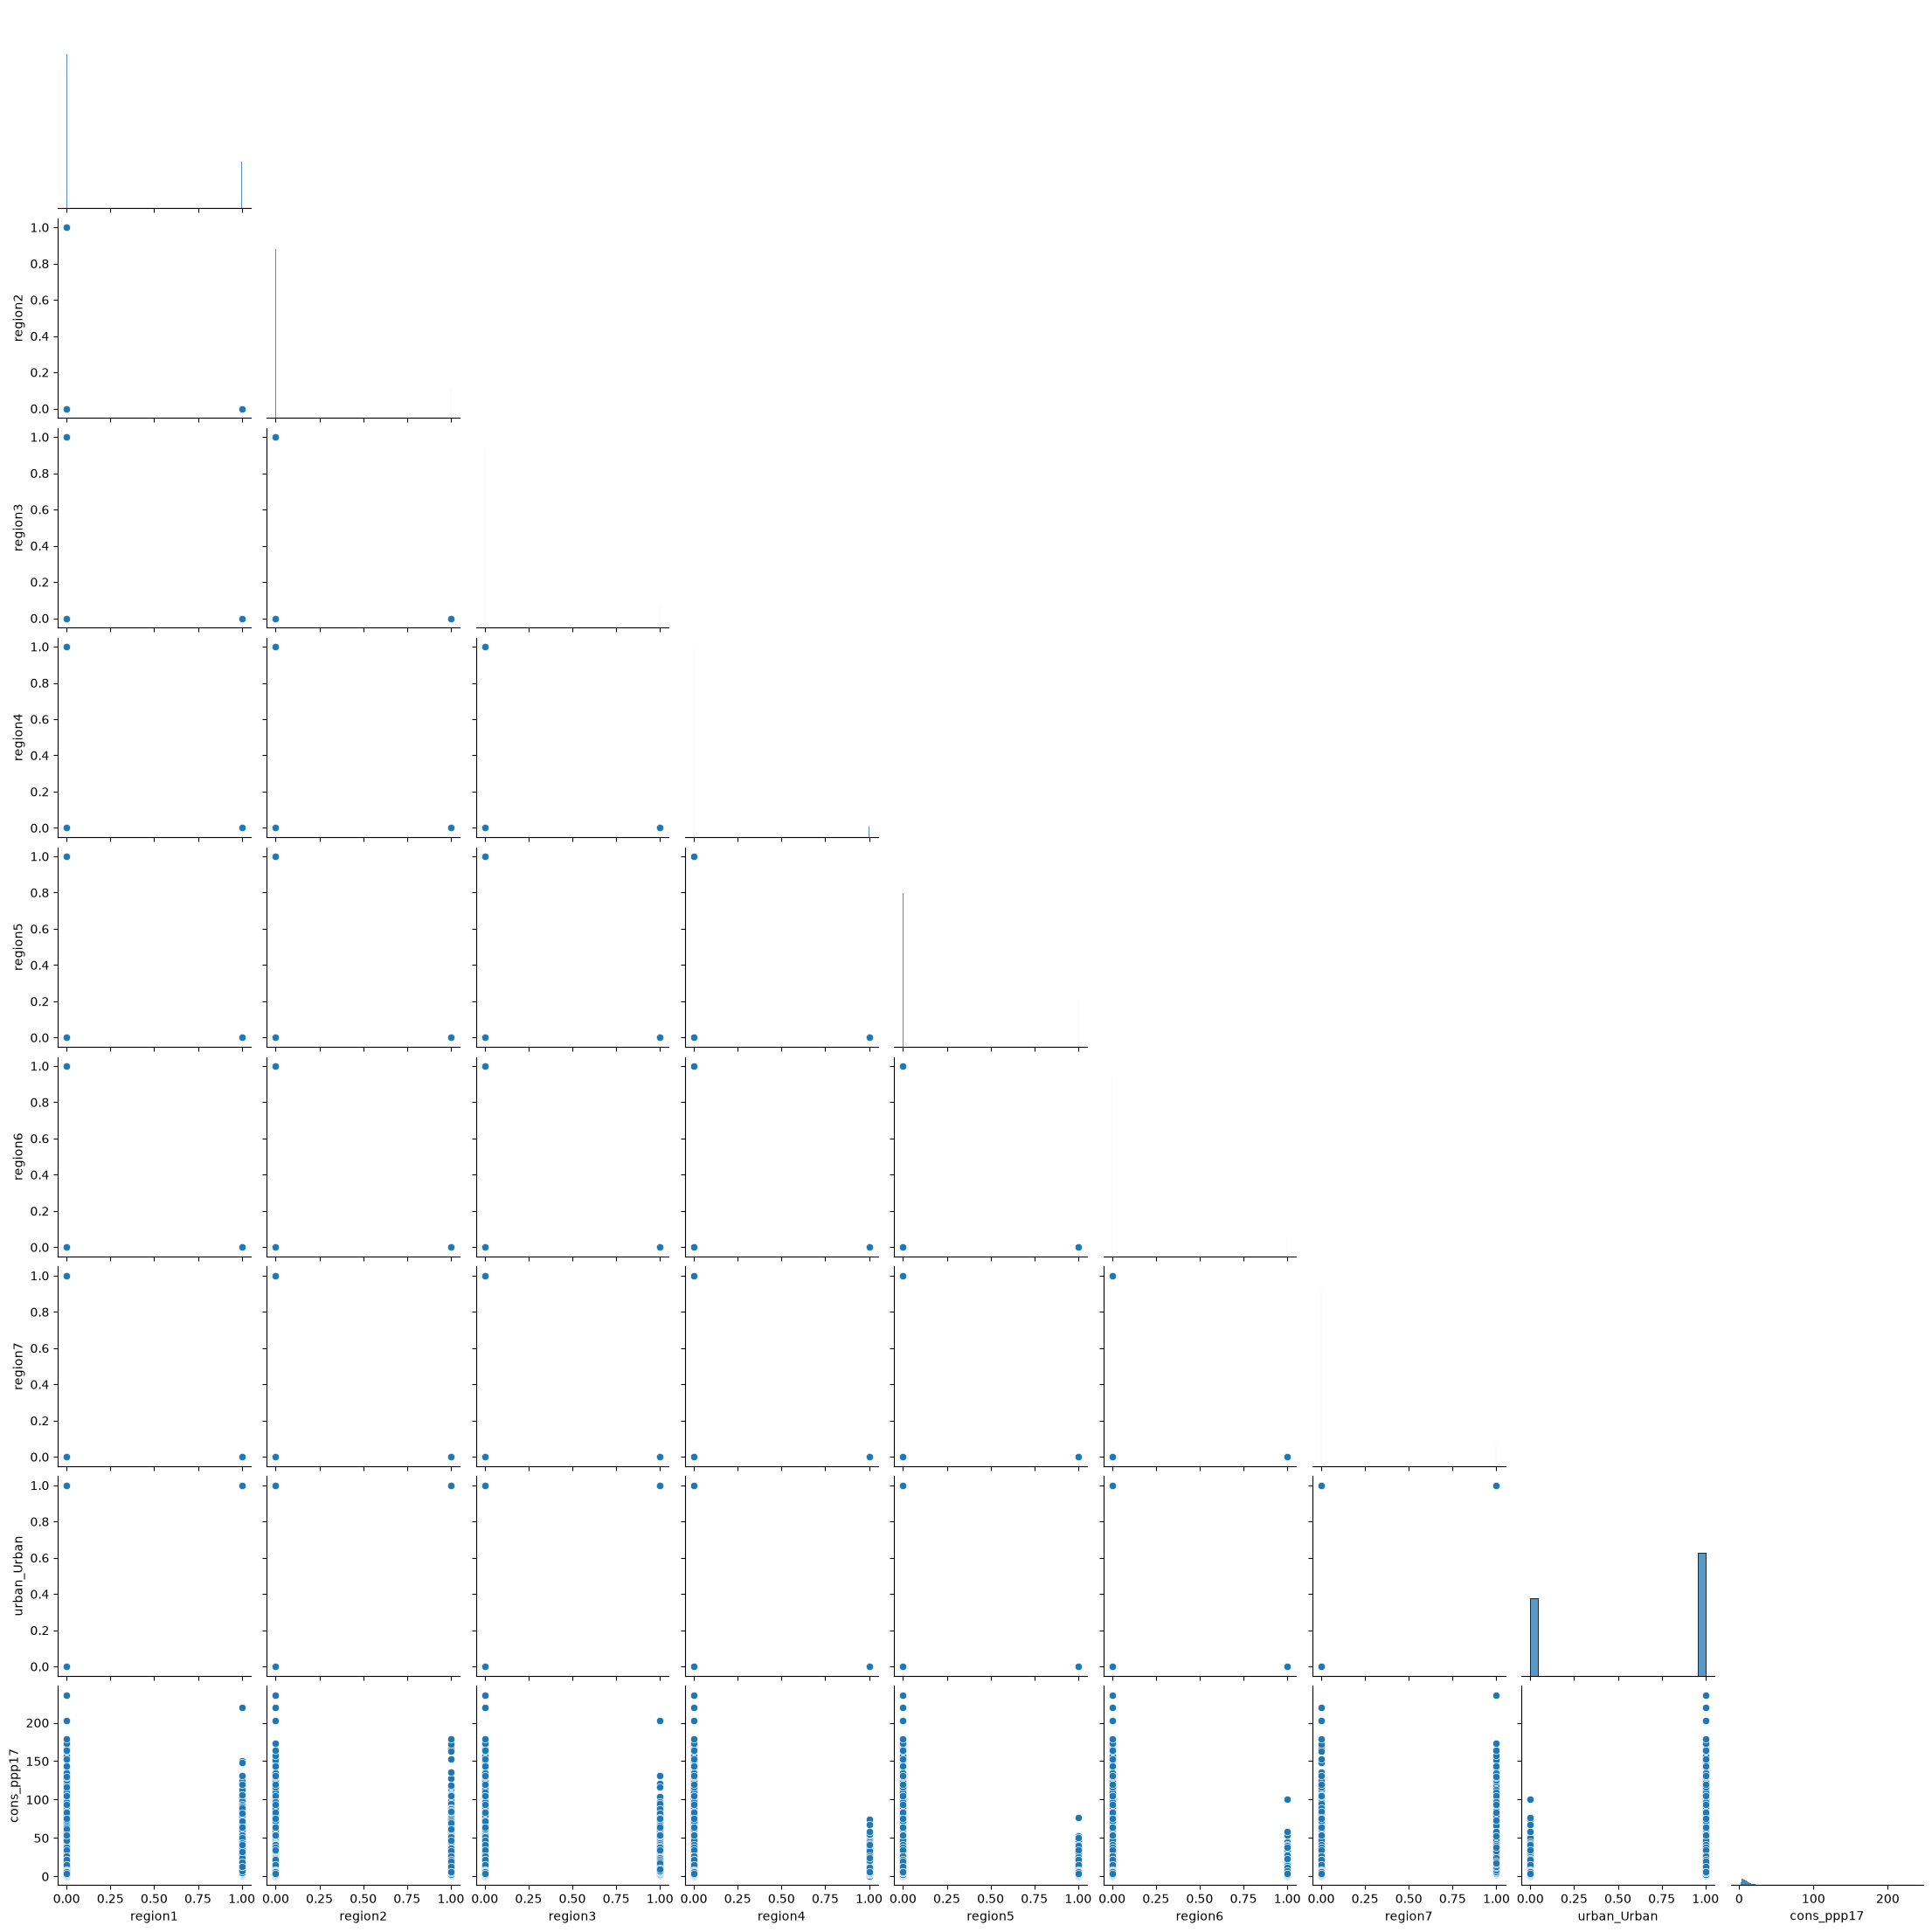

In [96]:
sns.pairplot(df[["region1", "region2", "region3", "region4", "region5", "region6", "region7", "urban_Urban", "cons_ppp17"]], corner= True)
# regions are either urban or rural as expected. 

In [98]:
df["dep_ratio"] = (df.num_children5 + df.num_children10) / df.hsize # not the exact definition of dependency raiton, but a still a good indicaotr of dependdency ration in this case
df["no_adult"] = np.where((df.num_adult_female == 0) & (df.num_adult_male == 0), 1, 0)
df["adult_female_ratio"] = df.num_adult_female / df.hsize
df = df.drop(["num_children5", "num_children10", "num_children18", "num_elderly", "num_adult_male", "num_adult_female", "region1", "region2", "region3", "region4", "region5", "region6", "region7"], axis =1)

<function matplotlib.pyplot.show(close=None, block=None)>

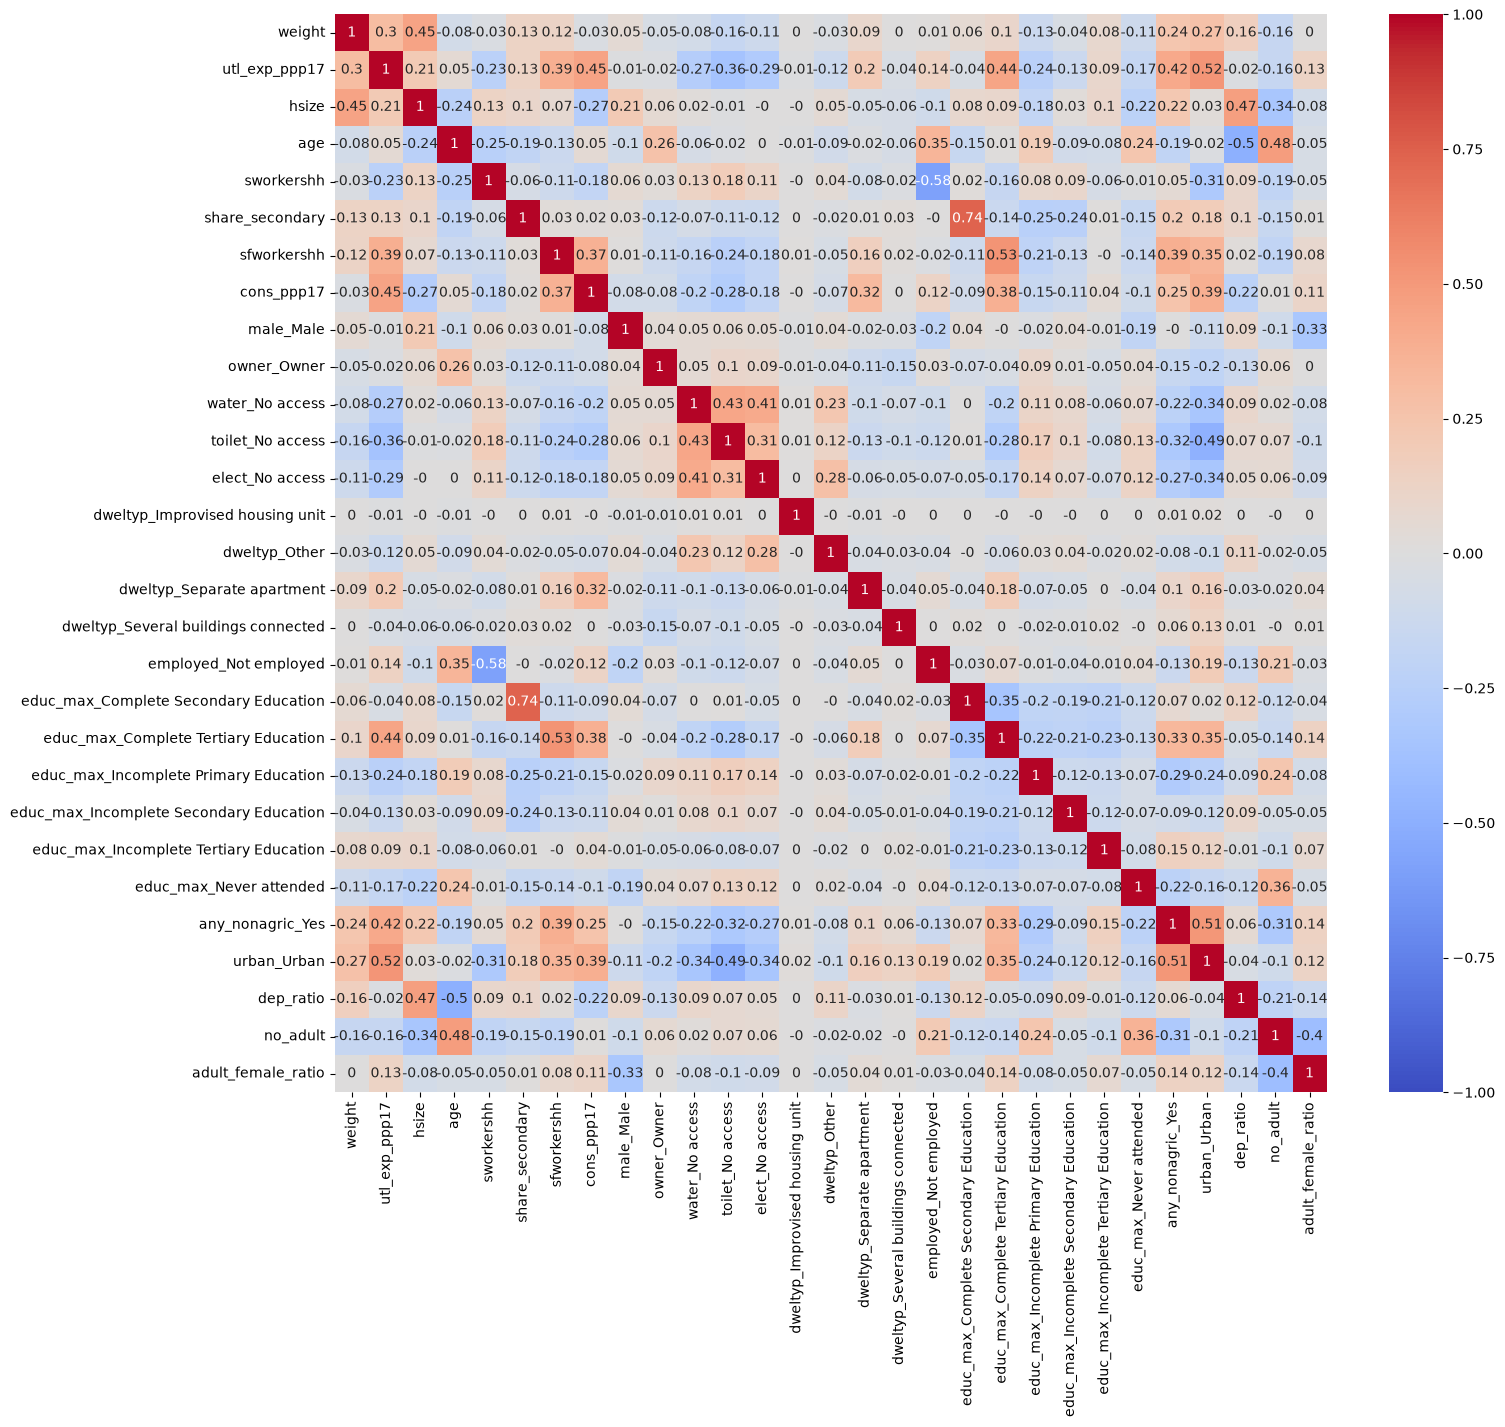

In [99]:
plt.figure(figsize= (16, 14))
sns.heatmap(round(df.corr(numeric_only= True),2), annot = True, vmin= -1, vmax= 1, cmap= "coolwarm");
plt.show

## EDA results: 

- Utl_exp_ppp, sworkershh, and hsize have comperatively highed correlations with consumption.
- hsize and several household characteristics (numbe rof children and adults features) have correlations coefficients larger than 0.5.
- There are Urban and Rural regions; for predicting consumption rural urban difference is more predictive than any comparision of regions. 

Lessons learned: 
- I tried to account for number of dependents in the household. Households have in general many children and thus number of dependents had around 0.77 correlation with the household size - thus not included here. 
- There is a variable that captures the share of adults with secondary education and educ_max variable which captures the max education in the household. The latter may include also the cildren, but for income generation, thus for consumption prediction former is conceptually a better feature to consider. This I will assume in linear regression, but for other models, I will let models to decide.  

In [100]:
df.to_pickle("../data/df.pkl")